# Síntese Geral e Análise de Compromisso: Os 4 Algoritmos

**Objetivo:** Consolidar OrderBased, AisleBased, ILS-VND e Referência (`andre_feijo`) nos datasets A, B e X ($50$ instâncias), com teste de Friedman, pós-teste (Nemenyi e Wilcoxon/Holm) e análise de compromisso qualidade $\times$ tempo.

## Tabelas e Figuras Geradas

| Identificador | Conteúdo | Objetivo |
|:---:|---|---|
| **T4.1** (`tab_4_1`) | Quadro sinótico global + Friedman | Gap mediano/médio, taxa de Gap $\le 1\%$, tempo médio, rank médio de Friedman e $p$ ajustado (Holm e Nemenyi) contra o líder em ranking |
| **T4.1b** (`tab_4_1b`) | Comparações par a par | $p$ de Nemenyi e de Wilcoxon (Holm) para os 6 pares |
| **T4.2** (`tab_4_2`) | Resultados por instância (Apêndice) | MSC ($f^*$), objetivo e gap dos 4 métodos; melhor gap da linha em negrito (`longtable`) |
| **F4.1** (`fig_4_1`) | Diagrama de Diferença Crítica | Ranking médio de Friedman; barras ligam algoritmos sem diferença significativa (Nemenyi, $\alpha = 0{,}05$) |
| **F4.2** (`fig_4_2`) | Trade-off global | Tempo médio (escala log) $\times$ gap médio, com os regimes de tempo real e de planejamento |

## Convenções do Estudo

- **Unidade estatística:** instância ($N = 50$). Para cada instância e método usa-se a **média do gap** das execuções: AisleBased e OrderBased com todas as execuções disponíveis (como em `comparacao_construtivas_final`); ILS-VND e Referência com as 5 primeiras réplicas (`run_id` $\le 5$, como em `comparacao_metaheuristicas`).
- **Gap (%):** $\frac{\text{MSC} - \text{obtido}}{\text{MSC}} \times 100$ (maximização; negativo indica MSC superada).
- **Ranks de Friedman:** por instância, o menor gap recebe rank $1$ (empates com tolerância $10^{-9}$ recebem o rank médio).
- **Nemenyi:** $CD = q_{\alpha}\sqrt{k(k+1)/(6N)}$ com $q_{0,05} = 2{,}569$ para $k = 4$; $p$ via distribuição da amplitude studentizada.
- **Holm:** Wilcoxon pareado bilateral sobre o gap por instância, com correção de Holm para as 6 comparações.
- **Tempo:** média, entre instâncias, do tempo médio de execução (`exec_time`) por instância.

## 1. Configuração

In [1]:
import sys
import os
from pathlib import Path

# ── Localização da raiz do repositório ───────────────────────────────────────
_candidate = Path.cwd()
ROOT = None
for _p in [_candidate] + list(_candidate.parents):
    if (_p / "notebooks" / "utils" / "__init__.py").exists():
        ROOT = _p
        break
if ROOT is None:
    raise RuntimeError("Raiz do repositório não encontrada (notebooks/utils/__init__.py ausente).")

# ── Caminhos principais ───────────────────────────────────────────────────────
RESULTS_BASE   = ROOT / "project" / "results"
BEST_OBJ_CSV   = ROOT / "best_solutions" / "best_objectives.csv"
OUTPUT_DIR     = ROOT / "notebooks" / "experimentos" / "output" / "sintese_geral"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for _d in [str(ROOT / "notebooks"), str(ROOT)]:
    if _d not in sys.path:
        sys.path.insert(0, _d)

# ── Constantes ────────────────────────────────────────────────────────────────
TOL        = 1e-9
ALPHA      = 0.05
N_REPS     = 5                      # réplicas de ILS-VND e Referência (run_id 1..N_REPS)
DATASETS   = ["a", "b", "x"]
DS_LABELS  = {"a": "A", "b": "B", "x": "X"}
ALGOS       = ["order", "aisle", "ils_vnd", "ref"]
ALGO_LABELS = {"order": "OrderBased", "aisle": "AisleBased", "ils_vnd": "ILS-VND", "ref": "Referência"}
RESULT_DIRS = {"order": "order_based", "aisle": "aisle_based", "ils_vnd": "ils_vnd_all", "ref": "andre_feijo_all"}
MAX_RUN_ID  = {"order": None, "aisle": None, "ils_vnd": N_REPS, "ref": N_REPS}
COLORS  = {"order": "tab:orange", "aisle": "tab:blue", "ils_vnd": "tab:green", "ref": "tab:red"}
MARKERS = {"order": "s", "aisle": "^", "ils_vnd": "D", "ref": "o"}

FIG_W    = 6.3
FONT_MIN = 9

## 2. Utilitários

In [2]:
import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({"font.size": FONT_MIN, "axes.labelsize": FONT_MIN, "legend.fontsize": FONT_MIN,
                     "xtick.labelsize": FONT_MIN, "ytick.labelsize": FONT_MIN})

def fmt(value, decimals=2):
    """Formata número com vírgula como separador decimal."""
    if pd.isna(value):
        return "--"
    if isinstance(value, (int, np.integer)):
        return f"{int(value)}"
    return f"{value:.{decimals}f}".replace(".", ",")

def fmt_p(p):
    if pd.isna(p): return "--"
    return r"$<$ 0,001" if p < 0.001 else fmt(p, 3)

def tex_escape(text, raw=False):
    if raw:
        return str(text)
    s = str(text)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("#", r"\#"), ("_", r"\_"),
                 ("{", r"\{"), ("}", r"\}"), ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]:
        s = s.replace(a, b)
    return s

def make_tabular(header_rows, data_rows, col_align, raw_cols=None):
    raw_cols = raw_cols or set()
    def row_tex(row):
        out = []
        for j, cell in enumerate(row):
            txt, is_raw = cell if isinstance(cell, tuple) else (cell, j in raw_cols)
            out.append(tex_escape(str(txt), raw=is_raw))
        return " & ".join(out) + r" \\"
    lines = [r"\small", r"\begin{tabular}{" + col_align + "}", r"\toprule"]
    lines += [row_tex(h) for h in header_rows] + [r"\midrule"] + [row_tex(r) for r in data_rows]
    lines += [r"\bottomrule", r"\end{tabular}"]
    return "\n".join(lines)

def salvar_tabela(nome, df_csv, tex_str, output_dir=OUTPUT_DIR):
    df_csv.to_csv(output_dir / f"{nome}.csv", index=False)
    (output_dir / f"{nome}.tex").write_text(tex_str, encoding="utf-8")

def holm(pvals):
    """Correção de Holm-Bonferroni (step-down); preserva NaN."""
    p = np.asarray(pvals, float)
    idx = [i for i in np.argsort(np.where(np.isnan(p), np.inf, p)) if not np.isnan(p[i])]
    adj, prev, m = np.full_like(p, np.nan), 0.0, len(idx)
    for r, i in enumerate(idx):
        prev = max(prev, min(1.0, (m - r) * p[i]))
        adj[i] = prev
    return adj

def wilcoxon_p(x, y):
    d = np.asarray(x, float) - np.asarray(y, float)
    d = d[np.abs(d) > TOL]
    return np.nan if len(d) == 0 else stats.wilcoxon(d, alternative="two-sided", zero_method="wilcox").pvalue

def nemenyi_p(diff_rank, k, n):
    """p-valor de Nemenyi para a diferença de ranks médios (amplitude studentizada)."""
    q = abs(diff_rank) / np.sqrt(k * (k + 1) / (12.0 * n))
    return float(stats.studentized_range.sf(q, k, np.inf))

## 3. Carga dos Resultados, MSC e Gap

In [3]:
from utils.resultados import carregar_resultados

frames = []
for a in ALGOS:
    d = carregar_resultados(RESULT_DIRS[a], RESULTS_BASE)
    if MAX_RUN_ID[a] is not None:
        d = d[d["run_id"] <= MAX_RUN_ID[a]]
    d = d.copy(); d["algo"] = a
    frames.append(d)
df_raw = pd.concat(frames, ignore_index=True)

print("Execuções por algoritmo e dataset:")
display(df_raw.groupby(["algo", "dataset"]).size().unstack(fill_value=0).loc[ALGOS])
_inf = df_raw[df_raw["status"] != "feasible"]
print("Execuções não viáveis (descartadas):", len(_inf))
if len(_inf):
    display(_inf.groupby(["algo", "status"]).size())
df_viable = df_raw[df_raw["status"] == "feasible"].copy()

_m = pd.read_csv(BEST_OBJ_CSV)
_m["instance_key"] = _m["instance"].str.strip().str.replace("\r", "", regex=False).str.replace(".txt", "", regex=False)
_m["dataset"] = _m["dataset"].str.strip()
msc_dict = {(r["dataset"], r["instance_key"]): r["best_objective"] for _, r in _m.iterrows()}
df_viable["msc"] = [msc_dict.get(k, np.nan) for k in zip(df_viable["dataset"], df_viable["instance"])]
df_viable["gap"] = (df_viable["msc"] - df_viable["objective"]) / df_viable["msc"] * 100.0

df_inst = (df_viable.groupby(["dataset", "instance", "algo"])
           .agg(gap=("gap", "mean"), obj=("objective", "mean"), tempo=("exec_time", "mean"), msc=("msc", "first"))
           .reset_index())

def _pivot(col):
    p = df_inst.pivot(index=["dataset", "instance"], columns="algo", values=col)[ALGOS]
    return p.dropna()

GAP, OBJ, TEMPO = _pivot("gap"), _pivot("obj"), _pivot("tempo")
MSC = df_inst.groupby(["dataset", "instance"])["msc"].first().loc[GAP.index]
N = len(GAP); K = len(ALGOS)
print(f"Instâncias com os 4 métodos: {N}")
display(GAP.head())

Execuções por algoritmo e dataset:


dataset,a,b,x
algo,,,
order,600,450,450
aisle,600,450,450
gvns,100,75,75
ref,100,75,75


Execuções não viáveis (descartadas): 0
Instâncias com os 4 métodos: 50


algo                       order      aisle  gvns  ref
dataset instance                                      
a       instance_0001  65.128205   0.000000   0.0  0.0
        instance_0002   0.000000   0.000000   0.0  0.0
        instance_0003  61.594203  29.166667   0.0  0.0
        instance_0004  39.849624   0.000000   0.0  0.0
        instance_0005  80.233310   3.092059   0.0  0.0

## 4. Teste de Friedman e Pós-testes

**Hipótese nula:** os $k = 4$ algoritmos têm o mesmo desempenho (gap) nas $N = 50$ instâncias. Em caso de rejeição, aplicam-se Nemenyi (base do diagrama de diferença crítica) e Wilcoxon pareado com correção de Holm.

In [4]:
G = GAP.round(9).values
RANKS = np.apply_along_axis(stats.rankdata, 1, G)          # menor gap -> rank 1
mean_rank = pd.Series(RANKS.mean(axis=0), index=ALGOS)

chi2, p_fried = stats.friedmanchisquare(*[G[:, j] for j in range(K)])
# Estatística de Iman-Davenport (menos conservadora), como complemento
F_id = (N - 1) * chi2 / (N * (K - 1) - chi2)
p_id = stats.f.sf(F_id, K - 1, (K - 1) * (N - 1))
print(f"Friedman: chi2 = {chi2:.3f}, gl = {K-1}, p = {p_fried:.3e}")
print(f"Iman-Davenport: F = {F_id:.3f}, p = {p_id:.3e}")
display(mean_rank.rename(index=ALGO_LABELS).to_frame("Rank médio"))

Q_ALPHA = 2.569  # q_0,05 de Nemenyi para k = 4 (Demsar, 2006)
assert K == 4
CD = Q_ALPHA * np.sqrt(K * (K + 1) / (6.0 * N))
print(f"Diferença crítica (Nemenyi, alpha=0,05): CD = {CD:.3f}")

pairs = [(a, b) for i, a in enumerate(ALGOS) for b in ALGOS[i + 1:]]
rows = []
for a, b in pairs:
    dr = mean_rank[a] - mean_rank[b]
    rows.append({"a": a, "b": b, "dif_rank": dr, "p_nemenyi": nemenyi_p(dr, K, N),
                 "p_wilcoxon": wilcoxon_p(GAP[a].values, GAP[b].values)})
df_pairs = pd.DataFrame(rows)
df_pairs["p_holm"] = holm(df_pairs["p_wilcoxon"].values)
df_pairs["sig_nemenyi"] = df_pairs["dif_rank"].abs() > CD
display(df_pairs)

LEADER = mean_rank.idxmin()
print("Líder em ranking:", ALGO_LABELS[LEADER])

Friedman: chi2 = 130.109, gl = 3, p = 5.124e-28
Iman-Davenport: F = 320.508, p = 2.927e-64


,Rank médio
OrderBased,3.97
AisleBased,2.69
GVNS,1.76
Referência,1.58


Diferença crítica (Nemenyi, alpha=0,05): CD = 0.663


,a,b,dif_rank,p_nemenyi,p_wilcoxon,p_holm,sig_nemenyi
0,order,aisle,1.28,0.000004,3.552714e-15,2.131628e-14,True
1,order,gvns,2.21,0.000000,3.552714e-15,2.131628e-14,True
2,order,ref,2.39,0.000000,3.552714e-15,2.131628e-14,True
3,aisle,gvns,0.93,0.001795,1.164153e-10,3.492460e-10,True
4,aisle,ref,1.11,0.000101,1.164153e-10,3.492460e-10,True
5,gvns,ref,0.18,0.898221,2.322388e-02,2.322388e-02,False


Líder em ranking: Referência


## 5. Tabela 4.1: Quadro Sinótico Global e Friedman

### Legenda e Descrição das Colunas
* **Gap mediano / médio (%):** estatísticas do gap por instância (média das réplicas) sobre as 50 instâncias.
* **Gap $\le 1\%$:** número de instâncias (de 50) com gap $\le 1\%$.
* **Tempo médio (s):** média entre instâncias do tempo de execução.
* **Rank médio:** rank médio de Friedman (menor é melhor).
* **$p$ Holm / $p$ Nemenyi:** $p$ ajustado da comparação do algoritmo contra o líder em ranking (`--` para o próprio líder). Holm sobre Wilcoxon pareado (6 comparações); Nemenyi sobre a diferença de ranks médios.

In [5]:
def par_vs_lider(a):
    if a == LEADER:
        return np.nan, np.nan
    r = df_pairs[((df_pairs.a == a) & (df_pairs.b == LEADER)) | ((df_pairs.a == LEADER) & (df_pairs.b == a))].iloc[0]
    return r["p_holm"], r["p_nemenyi"]

csv41, tex41 = [], []
for a in ALGOS:
    g = GAP[a].values
    n_le1 = int((g <= 1 + TOL).sum())
    ph, pn = par_vs_lider(a)
    csv41.append({"Algoritmo": ALGO_LABELS[a], "Gap_mediano": np.median(g), "Gap_medio": g.mean(),
                  "Gap_le1_n": n_le1, "Gap_le1_N": N, "Tempo_medio_s": TEMPO[a].mean(),
                  "Rank_medio": mean_rank[a], "p_Holm_vs_lider": ph, "p_Nemenyi_vs_lider": pn})
    tex41.append([ALGO_LABELS[a], fmt(np.median(g)), fmt(g.mean()), (f"{n_le1}/{N}", False),
                  fmt(TEMPO[a].mean(), 2), fmt(mean_rank[a], 2), (fmt_p(ph), True), (fmt_p(pn), True)])
df_tab41 = pd.DataFrame(csv41)
HEADER_41 = [["Algoritmo", "Gap mediano (\\%)", "Gap médio (\\%)", (r"Gap $\leq$ 1\%", True), "Tempo médio (s)",
              "Rank médio", (r"$p$ Holm", True), (r"$p$ Nemenyi", True)]]
HEADER_41 = [[(h if isinstance(h, tuple) else (h, True)) for h in HEADER_41[0]]]
tex_41 = make_tabular(HEADER_41, tex41, "lrrrrrrr")
LEG_41 = "\n".join([
    "% Legenda:",
    "% - Gap mediano/medio: estatisticas do gap (%) por instancia (media das replicas), N = 50.",
    "% - Gap <= 1%: instancias com gap <= 1%.",
    "% - Tempo medio: media entre instancias do tempo de execucao (s).",
    "% - Rank medio: rank medio de Friedman (menor e melhor).",
    f"% - p Holm / p Nemenyi: p ajustado contra o lider ({ALGO_LABELS[LEADER]}); -- indica o proprio lider.",
    f"% - Friedman: chi2 = {chi2:.3f}, gl = {K-1}, p = {p_fried:.3e}; CD de Nemenyi = {CD:.3f}."])
salvar_tabela("tab_4_1", df_tab41, tex_41 + "\n\n" + LEG_41)
display(df_tab41); print(tex_41); print(LEG_41)

# Tabela 4.1b: comparações par a par
csv41b, tex41b = [], []
for _, r in df_pairs.iterrows():
    csv41b.append({"A": ALGO_LABELS[r.a], "B": ALGO_LABELS[r.b], "Dif_rank": r.dif_rank, "p_Nemenyi": r.p_nemenyi,
                   "Signif_Nemenyi": bool(r.sig_nemenyi), "p_Wilcoxon": r.p_wilcoxon, "p_Holm": r.p_holm})
    tex41b.append([ALGO_LABELS[r.a], ALGO_LABELS[r.b], fmt(r.dif_rank, 2), (fmt_p(r.p_nemenyi), True),
                   (fmt_p(r.p_wilcoxon), True), (fmt_p(r.p_holm), True)])
df_tab41b = pd.DataFrame(csv41b)
HEADER_41B = [["Algoritmo A", "Algoritmo B", (r"$\Delta$ rank", True), (r"$p$ Nemenyi", True),
               (r"$p$ Wilcoxon", True), (r"$p$ Holm", True)]]
tex_41b = make_tabular(HEADER_41B, tex41b, "llrrrr")
salvar_tabela("tab_4_1b", df_tab41b, tex_41b)
display(df_tab41b)

,Algoritmo,Gap_mediano,Gap_medio,Gap_le1_n,Gap_le1_N,Tempo_medio_s,Rank_medio,p_Holm_vs_lider,p_Nemenyi_vs_lider
0,OrderBased,88.754864,81.467682,1,50,15.918064,3.97,2.131628e-14,0.000000
1,AisleBased,0.732287,3.701257,28,50,2.023028,2.69,3.492460e-10,0.000101
2,GVNS,0.000000,0.180477,47,50,474.973564,1.76,2.322388e-02,0.898221
3,Referência,0.000000,0.019834,50,50,190.707424,1.58,NaN,NaN


\small
\begin{tabular}{lrrrrrrr}
\toprule
Algoritmo & Gap mediano (\%) & Gap médio (\%) & Gap $\leq$ 1\% & Tempo médio (s) & Rank médio & $p$ Holm & $p$ Nemenyi \\
\midrule
OrderBased & 88,75 & 81,47 & 1/50 & 15,92 & 3,97 & $<$ 0,001 & $<$ 0,001 \\
AisleBased & 0,73 & 3,70 & 28/50 & 2,02 & 2,69 & $<$ 0,001 & $<$ 0,001 \\
GVNS & 0,00 & 0,18 & 47/50 & 474,97 & 1,76 & 0,023 & 0,898 \\
Referência & 0,00 & 0,02 & 50/50 & 190,71 & 1,58 & -- & -- \\
\bottomrule
\end{tabular}
% Legenda:
% - Gap mediano/medio: estatisticas do gap (%) por instancia (media das replicas), N = 50.
% - Gap <= 1%: instancias com gap <= 1%.
% - Tempo medio: media entre instancias do tempo de execucao (s).
% - Rank medio: rank medio de Friedman (menor e melhor).
% - p Holm / p Nemenyi: p ajustado contra o lider (Referência); -- indica o proprio lider.
% - Friedman: chi2 = 130.109, gl = 3, p = 5.124e-28; CD de Nemenyi = 0.663.


,A,B,Dif_rank,p_Nemenyi,Signif_Nemenyi,p_Wilcoxon,p_Holm
0,OrderBased,AisleBased,1.28,0.000004,True,3.552714e-15,2.131628e-14
1,OrderBased,GVNS,2.21,0.000000,True,3.552714e-15,2.131628e-14
2,OrderBased,Referência,2.39,0.000000,True,3.552714e-15,2.131628e-14
3,AisleBased,GVNS,0.93,0.001795,True,1.164153e-10,3.492460e-10
4,AisleBased,Referência,1.11,0.000101,True,1.164153e-10,3.492460e-10
5,GVNS,Referência,0.18,0.898221,False,2.322388e-02,2.322388e-02


## 6. Tabela 4.2: Resultados por Instância (Apêndice)

Para cada instância: MSC ($f^*$) e, para cada método, o objetivo médio e o gap médio (%). Em **negrito**, o melhor (menor gap, tolerância $10^{-9}$) da linha; empates marcam todos os métodos empatados.

In [6]:
def fnum(x, d=2):
    return fmt(float(x), d)

rows_csv, rows_tex = [], []
for (ds, inst) in GAP.index:
    g = GAP.loc[(ds, inst)]
    best = g.min()
    r_csv = {"Dataset": DS_LABELS[ds], "Instancia": inst, "MSC": MSC.loc[(ds, inst)]}
    cells = [DS_LABELS[ds], inst.replace("instance_", ""), fnum(MSC.loc[(ds, inst)])]
    for a in ALGOS:
        win = g[a] <= best + TOL
        r_csv[f"{ALGO_LABELS[a]}_obj"] = OBJ.loc[(ds, inst), a]
        r_csv[f"{ALGO_LABELS[a]}_gap"] = g[a]
        r_csv[f"{ALGO_LABELS[a]}_melhor"] = bool(win)
        o, gg = fnum(OBJ.loc[(ds, inst), a]), fnum(g[a])
        cells += [(r"\textbf{" + o + "}" if win else o), (r"\textbf{" + gg + "}" if win else gg)]
    rows_csv.append(r_csv)
    rows_tex.append(cells)
df_tab42 = pd.DataFrame(rows_csv)

_h1 = [r"\multirow{2}{*}{Dataset}", r"\multirow{2}{*}{Inst.}", r"\multirow{2}{*}{MSC ($f^*$)}"] + \
      [r"\multicolumn{2}{c}{" + ALGO_LABELS[a] + "}" for a in ALGOS]
_h2 = ["", "", ""] + ["Obj.", r"Gap (\%)"] * K
_cmid = " ".join([rf"\cmidrule(lr){{{4 + 2*i}-{5 + 2*i}}}" for i in range(K)])
tex_42 = "\n".join([
    r"\footnotesize",
    r"\begin{longtable}{llr" + "rr" * K + "}",
    r"\toprule", " & ".join(_h1) + r" \\", _cmid, " & ".join(_h2) + r" \\", r"\midrule", r"\endfirsthead",
    r"\toprule", " & ".join(_h1) + r" \\", _cmid, " & ".join(_h2) + r" \\", r"\midrule", r"\endhead",
    r"\bottomrule", r"\endfoot",
    *[" & ".join(c) + r" \\" for c in rows_tex],
    r"\end{longtable}"])
LEG_42 = "\n".join([
    "% Legenda:",
    "% - Inst.: numero da instancia no dataset. MSC: melhor solucao conhecida (f*).",
    "% - Obj./Gap: objetivo medio e gap medio (%) das execucoes; negrito = menor gap da linha (empates em negrito).",
    "% - Requer pacotes booktabs, longtable e multirow."])
salvar_tabela("tab_4_2", df_tab42, tex_42 + "\n\n" + LEG_42)

wins = pd.DataFrame({ALGO_LABELS[a]: [int(df_tab42[f"{ALGO_LABELS[a]}_melhor"].sum())] for a in ALGOS}, index=["Linhas com melhor resultado (incl. empates)"])
display(wins)
display(df_tab42.head(10))

,OrderBased,AisleBased,GVNS,Referência
Linhas com melhor resultado (incl. empates),1,15,37,46


,Dataset,Instancia,MSC,OrderBased_obj,OrderBased_gap,OrderBased_melhor,AisleBased_obj,AisleBased_gap,AisleBased_melhor,GVNS_obj,GVNS_gap,GVNS_melhor,Referência_obj,Referência_gap,Referência_melhor
0,A,instance_0001,15.000000,5.230769,65.128205,False,15.000000,0.000000,True,15.000000,0.000000,True,15.000000,0.000000,True
1,A,instance_0002,2.000000,2.000000,0.000000,True,2.000000,0.000000,True,2.000000,0.000000,True,2.000000,0.000000,True
2,A,instance_0003,12.000000,4.608696,61.594203,False,8.500000,29.166667,False,12.000000,0.000000,True,12.000000,0.000000,True
3,A,instance_0004,3.500000,2.105263,39.849624,False,3.500000,0.000000,True,3.500000,0.000000,True,3.500000,0.000000,True
4,A,instance_0005,177.875000,35.160000,80.233310,False,172.375000,3.092059,False,177.875000,0.000000,True,177.875000,0.000000,True
5,A,instance_0006,691.000000,31.901639,95.383265,False,691.000000,0.000000,True,691.000000,0.000000,True,691.000000,0.000000,True
6,A,instance_0007,392.250000,28.708955,92.680955,False,392.250000,0.000000,True,392.250000,0.000000,True,392.250000,0.000000,True
7,A,instance_0008,162.941176,32.261364,80.200607,False,146.631579,10.009500,False,161.775000,0.715704,False,162.647059,0.180505,True
8,A,instance_0009,4.416667,2.942308,33.381713,False,3.040000,31.169811,False,4.416667,0.000000,True,4.416667,0.000000,True
9,A,instance_0010,17.112245,6.235714,63.559928,False,14.923077,12.792991,False,16.721524,2.283282,False,17.078431,0.197598,True


## 7. Figura 4.1: Diagrama de Diferença Crítica

Eixo de ranking médio de Friedman (melhores algoritmos à direita). Barras grossas conectam grupos cujos ranks médios diferem menos que $CD$ (Nemenyi, $\alpha = 0{,}05$), isto é, sem diferença estatística demonstrada.

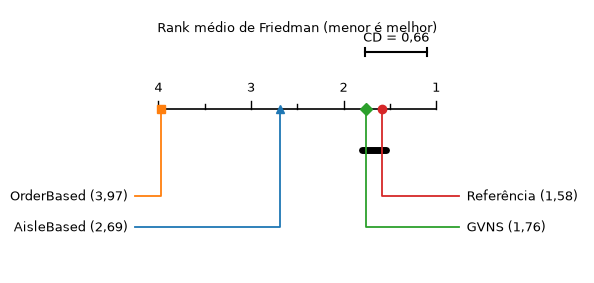

Grupos de empate técnico: [['Referência', 'GVNS']]


In [7]:
order = mean_rank.sort_values()            # melhor primeiro
names, rk = list(order.index), order.values

# Grupos (cliques) maximais em ordem de rank
cliques, last_j = [], -1
for i in range(K):
    j = max(jj for jj in range(i, K) if rk[jj] - rk[i] < CD)
    if j > i and j > last_j:
        cliques.append((i, j)); last_j = j

lo, hi = np.floor(rk.min()), np.ceil(rk.max())
if hi - lo < 2: lo, hi = lo - 0.5, hi + 0.5
xpos = lambda r: hi - r                    # rank menor -> mais à direita
BAR_DY, LBL_DY = 0.28, 0.42
y_bars0 = -0.55
n_cl = len(cliques)
y_lbl0 = y_bars0 - BAR_DY * n_cl - 0.35

fig, ax = plt.subplots(figsize=(FIG_W, 2.9))
ax.set_xlim(-1.6, hi - lo + 1.6); ax.set_ylim(y_lbl0 - LBL_DY * 2 - 0.2, 1.35)
ax.axis("off")
ax.plot([0, hi - lo], [0, 0], "k", lw=1.2)
for t in np.arange(lo, hi + 1e-9, 0.5):
    major = abs(t - round(t)) < 1e-9
    ax.plot([xpos(t)] * 2, [0, 0.12 if major else 0.07], "k", lw=1)
    if major: ax.text(xpos(t), 0.2, f"{int(round(t))}", ha="center", va="bottom", fontsize=FONT_MIN)
ax.text((hi - lo) / 2, 1.05, "Rank médio de Friedman (menor é melhor)", ha="center", fontsize=FONT_MIN)

# Barra de CD
x0 = xpos(lo + 0.1)
ax.plot([x0, x0 - CD], [0.78, 0.78], "k", lw=1.5)
for xx in (x0, x0 - CD): ax.plot([xx, xx], [0.72, 0.84], "k", lw=1.5)
ax.text(x0 - CD / 2, 0.88, f"CD = {fmt(CD, 2)}", ha="center", va="bottom", fontsize=FONT_MIN)

# Barras de empate técnico
for c, (i, j) in enumerate(cliques):
    y = y_bars0 - BAR_DY * c
    ax.plot([xpos(rk[i]) + 0.04, xpos(rk[j]) - 0.04], [y, y], "k", lw=5, solid_capstyle="round")

# Rótulos: metade melhor à direita, metade pior à esquerda
half = K // 2
for idx, (nm, r) in enumerate(zip(names, rk)):
    right = idx < half
    k_in_side = idx if right else (K - 1 - idx)
    y = y_lbl0 - LBL_DY * k_in_side
    xe = hi - lo + 0.25 if right else -0.25
    ax.plot([xpos(r), xpos(r), xe], [0, y, y], color=COLORS[nm], lw=1.3)
    ax.plot([xpos(r)], [0], marker=MARKERS[nm], color=COLORS[nm], ms=6)
    ax.text(xe + (0.08 if right else -0.08), y, f"{ALGO_LABELS[nm]} ({fmt(r, 2)})",
            ha="left" if right else "right", va="center", fontsize=FONT_MIN)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_4_1.pdf", bbox_inches="tight"); fig.savefig(OUTPUT_DIR / "fig_4_1.png", dpi=200, bbox_inches="tight")
pd.DataFrame({"algoritmo": [ALGO_LABELS[n] for n in names], "rank_medio": rk, "CD": CD}).to_csv(OUTPUT_DIR / "fig_4_1_dados.csv", index=False)
plt.show()
print("Grupos de empate técnico:", [[ALGO_LABELS[names[k]] for k in range(i, j + 1)] for i, j in cliques])

## 8. Figura 4.2: Trade-off Global (Tempo $\times$ Gap Médio)

Cada algoritmo é posicionado por (tempo médio de execução em escala logarítmica, gap médio sobre as 50 instâncias); barras verticais mostram o erro padrão do gap médio entre instâncias. As faixas sombreadas delimitam o regime de tempo real ($< 1$ s) e o de planejamento ($\approx 600$ s).

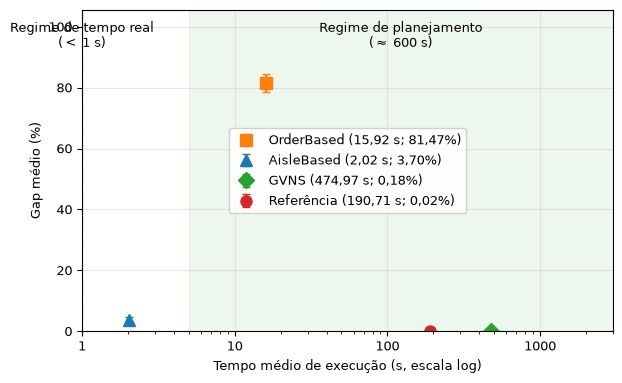

In [8]:
t_mean = TEMPO.mean(); g_mean = GAP.mean(); g_sem = GAP.std(ddof=1) / np.sqrt(N)

fig, ax = plt.subplots(figsize=(FIG_W, 3.9))
xmin, xmax = 10 ** np.floor(np.log10(t_mean.min()) - 0.3), 3000
ax.axvspan(xmin, 1.0, color="tab:blue", alpha=0.08)
ax.axvspan(5.0, xmax, color="tab:green", alpha=0.08)
ax.axvline(1.0, color="gray", ls="--", lw=0.8)
for a in ALGOS:
    ax.errorbar(t_mean[a], g_mean[a], yerr=g_sem[a], fmt=MARKERS[a], color=COLORS[a], ms=8, capsize=3,
                label=f"{ALGO_LABELS[a]} ({fmt(t_mean[a], 2)} s; {fmt(g_mean[a], 2)}%)")
ax.set_xscale("log"); ax.set_xlim(xmin, xmax)
ax.set_xlabel("Tempo médio de execução (s, escala log)"); ax.set_ylabel("Gap médio (%)")
ymax = (g_mean + g_sem).max() * 1.25
ax.set_ylim(min(0, (g_mean - g_sem).min() * 1.2), ymax)
ax.text(np.sqrt(xmin * 1.0), ymax * 0.97, "Regime de tempo real\n($<$ 1 s)", ha="center", va="top", fontsize=FONT_MIN)
ax.text(np.sqrt(5.0 * xmax), ymax * 0.97, r"Regime de planejamento" + "\n" + r"($\approx$ 600 s)", ha="center", va="top", fontsize=FONT_MIN)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
ax.grid(alpha=0.3, which="major"); ax.legend(loc="center", bbox_to_anchor=(0.5, 0.5), framealpha=0.9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_4_2.pdf", bbox_inches="tight"); fig.savefig(OUTPUT_DIR / "fig_4_2.png", dpi=200, bbox_inches="tight")
pd.DataFrame({"algoritmo": [ALGO_LABELS[a] for a in ALGOS], "tempo_medio_s": t_mean[ALGOS].values,
              "gap_medio": g_mean[ALGOS].values, "gap_sem": g_sem[ALGOS].values}).to_csv(OUTPUT_DIR / "fig_4_2_dados.csv", index=False)
plt.show()

## 9. Verificações Finais

In [9]:
_checks = []
def check(nome, cond, detalhe=""):
    _checks.append({"verificação": nome, "status": "ok" if cond else "FALHA", "detalhe": detalhe})
check("50 instâncias com os 4 métodos", N == 50, str(N))
check("sem ausentes", not GAP.isna().any().any())
check("ranks somam k(k+1)/2 por instância", np.allclose(RANKS.sum(axis=1), K * (K + 1) / 2))
check("soma dos ranks médios", np.isclose(mean_rank.sum(), K * (K + 1) / 2))
check("p-valores em [0,1]", bool(df_pairs[["p_nemenyi", "p_holm"]].dropna().apply(lambda c: c.between(0, 1)).all().all()))
check("Holm >= Wilcoxon bruto", bool((df_pairs.p_holm.dropna() >= df_pairs.p_wilcoxon.dropna() - 1e-12).all()))
check("tabela 4.2 com 50 linhas", len(df_tab42) == 50)
check("toda linha da 4.2 tem ao menos um melhor", all(df_tab42[[f"{ALGO_LABELS[a]}_melhor" for a in ALGOS]].any(axis=1)))
check("tempos positivos", bool((TEMPO > 0).all().all()))
for f in ["tab_4_1.tex", "tab_4_1b.tex", "tab_4_2.tex", "fig_4_1.pdf", "fig_4_2.pdf"]:
    check(f"arquivo gerado: {f}", (OUTPUT_DIR / f).exists())
df_checks = pd.DataFrame(_checks); display(df_checks)
if (df_checks["status"] == "FALHA").any():
    raise AssertionError("Falha em verificações!")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f.name:30s} {f.stat().st_size:8d} bytes")

,verificação,status,detalhe
0,50 instâncias com os 4 métodos,ok,50
1,sem ausentes,ok,
2,ranks somam k(k+1)/2 por instância,ok,
3,soma dos ranks médios,ok,
4,"p-valores em [0,1]",ok,
5,Holm >= Wilcoxon bruto,ok,
6,tabela 4.2 com 50 linhas,ok,
7,toda linha da 4.2 tem ao menos um melhor,ok,
8,tempos positivos,ok,
9,arquivo gerado: tab_4_1.tex,ok,


  fig_4_1.pdf                       17237 bytes
  fig_4_1.png                       36633 bytes
  fig_4_1_dados.csv                   159 bytes
  fig_4_2.pdf                       23120 bytes
  fig_4_2.png                       78631 bytes
  fig_4_2_dados.csv                   303 bytes
  tab_4_1.csv                         482 bytes
  tab_4_1.tex                         911 bytes
  tab_4_1b.csv                        648 bytes
  tab_4_1b.tex                        548 bytes
  tab_4_2.csv                        7552 bytes
  tab_4_2.tex                        7104 bytes
